# Are Post-2011 Equity Returns More Predictable in Downturns?
**Reproducing and extending the Ch. 8 equity return predictability table, CRSP, Compustat and FRED, 1926-2025**

Run top to bottom. Inputs: the files in `data/` (Section 2). No internet access or WRDS login is needed.

**Slide numbers.** The distributed deck differs from the assignment: the predictability tables are deck slides 28, 32 and 34 (assignment 24-25); buckets 37-39 (26-28); GARCH 41-43 (31-33).

## 1. Research question, economic rationale and audience

**Question.** Are post-2011 equity returns more predictable during economic downturns than during normal market conditions?

**Why predictability might be stronger in bad times.** The slides link the market risk premium to risk aversion and volatility: $E(r_m)-r_f=\bar\gamma\sigma_m^2$. In recessions, investors may become more risk averse while volatility rises. Prices fall today as investors demand higher returns, so high valuation ratios or weak economic conditions may precede higher returns. This motivates testing whether the relationship changes in downturns; it does not guarantee that downturn correlations will be stronger.

**Why after 2011?** The lecture table ends in 2011. Extending it tests whether the historical relationships survive a period of low dividend yields, high equity returns and several sharp stress episodes.

**Testable predictions (the hypothesis can fail).**

1. Valuation ratios predict future excess returns with positive signs, more strongly at longer horizons.
2. Predictors are more strongly related to future returns in downturns than in normal months.
3. That difference remains after 2011.
4. Volatility is more predictable than expected returns, as concluded in class.

**Intended audience.** Pension fund managers and long-term institutional investors deciding whether valuation and macro signals should affect strategic equity allocation or risk budgets.

**Roadmap.** Sections 2-4 data, returns and lecture replication; 5 dividend discount model and buckets; 6 volatility; 7 sensitivity; 8 downturn tests; 9 results; 10 conclusion and limitations; 11 requirements checklist.

## 2. Data, sample and cleaning

| File in `data/` | Source | Used for |
|---|---|---|
| `crsp_index.csv` | WRDS CRSP monthly market index, 1926-2025 | Total returns `vwretd` and `ewretd`; price return `vwretx` to infer dividends |
| `crsp_stock_compact.csv` | WRDS CRSP ordinary US common shares | Monthly market value for valuation ratios |
| `compustat_annual.csv` | WRDS Compustat annual fundamentals | Earnings `ib`; common dividends `dvc` for sensitivity |
| `ccm_links.csv` | WRDS CRSP-Compustat link table | Security-to-company matching with valid dates |
| `cay_current.csv` | Martin Lettau's data page, Lettau and Ludvigson | Quarterly consumption-wealth ratio, 1952-2019 |
| FRED `*.csv` | Federal Reserve Bank of St. Louis | Rates, spreads, CPI, industrial production, unemployment, GDP, oil, VIX and NBER recessions |
| `lecture_benchmarks.csv` | Ch. 8 tables, transcribed | The 56 lecture correlations and t-statistics |

**Returns.** `vwretd` is CRSP's value-weighted **total return**, including dividends and other distributions. No manual split adjustment is needed for the index. Individual stocks are used for market value, not for constructing returns. The main analysis uses excess returns over a T-bill proxy; equal-weighted and nominal returns are sensitivity tests.

**Calendar.** Every series is keyed by calendar month, aligning CRSP trading dates with FRED observation dates.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
pd.set_option("display.max_colwidth", 90)
cleaning_log = []

def log_step(dataset, step, affected, remaining, note=""):
    cleaning_log.append(dict(dataset=dataset, step=step, obs_affected=int(affected),
                             obs_remaining=int(remaining), note=note))

def month_ord(dates):
    # Calendar month as an integer (same numbering as pandas monthly Periods).
    return (dates.dt.year - 1970) * 12 + dates.dt.month - 1

def to_period(ords):
    return pd.PeriodIndex.from_ordinals(np.asarray(ords, dtype="int64"), freq="M")

**What this does:** imports the libraries and defines the calendar-month helpers and `log_step`, which records how many observations each cleaning step affects.

### 2a. CRSP market index: returns and dividend yield

In [2]:
crsp = pd.read_csv(DATA / "crsp_index.csv", parse_dates=["mthcaldt"])
crsp["month"] = crsp["mthcaldt"].dt.to_period("M")
dups = crsp["month"].duplicated().sum()
crsp = crsp.drop_duplicates("month", keep="last").set_index("month").sort_index()
log_step("CRSP index", "Duplicate months removed", dups, len(crsp))
log_step("CRSP index", "Months with a missing return",
         crsp[["vwretd", "vwretx", "ewretd", "ewretx"]].isna().any(axis=1).sum(), len(crsp))
log_step("CRSP index", "Gaps in the monthly calendar",
         len(pd.period_range(crsp.index.min(), crsp.index.max(), freq="M").difference(crsp.index)), len(crsp))
log_step("CRSP index", "Return incl. dividends < return excl. dividends (should be 0)",
         (crsp["vwretd"] < crsp["vwretx"] - 1e-9).sum(), len(crsp))

P = (1 + crsp["vwretx"]).cumprod()
D = (crsp["vwretd"] - crsp["vwretx"]) * P.shift(1).fillna(1.0)
crsp["div_yield"] = D.rolling(12).sum() / P
log_step("CRSP index", "Dividend yield undefined (first 11 months)", crsp["div_yield"].isna().sum(),
         crsp["div_yield"].notna().sum())
print(f"{len(crsp)} months, {crsp.index.min()} to {crsp.index.max()}")
print(crsp.loc[["1929-10", "1987-10", "2008-10", "2020-03"], "vwretd"].round(4).to_dict())

1200 months, 1926-01 to 2025-12
{Period('1929-10', 'M'): -0.1967, Period('1987-10', 'M'): -0.2254, Period('2008-10', 'M'): -0.1848, Period('2020-03', 'M'): -0.1417}


**What this does:** loads 1,200 monthly observations (Jan 1926 - Dec 2025) and constructs the dividend yield.

- Checks duplicate months, missing returns, calendar gaps and returns with dividends below returns without dividends; all counts are zero.
- Infers monthly dividends as $D_t=(\text{vwretd}_t-\text{vwretx}_t)P_{t-1}$, where $P$ is the price-only index. The yield is trailing 12-month dividends divided by $P_t$, first available in Dec 1926.
- Prints four crash months as a return sanity check.

### 2b. Earnings yield: Compustat earnings over current CRSP market value

In [3]:
DS = "Valuation ratios"
ca = pd.read_csv(DATA / "compustat_annual.csv", parse_dates=["datadate"], low_memory=False)
n = len(ca)
ca = ca[(ca["indfmt"] == "INDL") & (ca["datafmt"] == "STD") & (ca["consol"] == "C") & (ca["curcd"] == "USD")]
log_step(DS, "Compustat: non-standard records removed", n - len(ca), len(ca))
n = len(ca); ca = ca.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "datadate"], keep="last")
log_step(DS, "Compustat: duplicate firm-dates removed", n - len(ca), len(ca))
n = len(ca); ca = ca.drop_duplicates(["gvkey", "fyear"], keep="last")
log_step(DS, "Compustat: repeated fiscal years removed (kept later report)", n - len(ca), len(ca))

stock = pd.read_csv(DATA / "crsp_stock_compact.csv", parse_dates=["MthCalDt"])
n = len(stock); stock = stock.drop_duplicates()
log_step(DS, "CRSP stocks: exact duplicate security-months removed", n - len(stock), len(stock))
n = len(stock); stock = stock[stock["MthCap"] > 0]
log_step(DS, "CRSP stocks: non-positive market value removed", n - len(stock), len(stock))
stock["month"] = month_ord(stock["MthCalDt"])

links = pd.read_csv(DATA / "ccm_links.csv")
n = len(links); links = links[links["LINKTYPE"].isin(["LC", "LU"]) & links["LINKPRIM"].isin(["P", "C"])].copy()
log_step(DS, "CCM: links that are not primary LC/LU removed", n - len(links), len(links))
links["start"] = month_ord(pd.to_datetime(links["LINKDT"]))
links["end"] = month_ord(pd.to_datetime(links["LINKENDDT"], errors="coerce")).fillna(10**6)   # "E" = still active
m = stock.merge(links[["gvkey", "LPERMNO", "start", "end", "LINKPRIM"]], left_on="PERMNO", right_on="LPERMNO")
m = m[(m["month"] >= m["start"]) & (m["month"] <= m["end"])]
n = len(m); m = m.sort_values("LINKPRIM", key=lambda s: s.map({"P": 0, "C": 1})).drop_duplicates(["PERMNO", "month"])
log_step(DS, "CRSP stocks: two valid links in a month (kept the primary one)", n - len(m), len(m))
log_step(DS, "CRSP stocks: no valid link to Compustat (not used)", len(stock) - len(m), len(m))
cap = m.groupby(["gvkey", "month"], as_index=False)["MthCap"].sum()      # $ thousands, summed over share classes
del stock, m

def market_yield(item, label, min_firms=500):
    # Sum of `item` over firms / their current market value, using each firm's latest report
    # from 6 months after fiscal year end, for at most 12 months (the newest report wins).
    rep = ca.dropna(subset=[item]).reset_index(drop=True)
    log_step(DS, f"{label}: Compustat reports without {item} not used", len(ca) - len(rep), len(rep))
    rep["avail"] = month_ord(rep["datadate"]) + 6
    acct = rep.loc[rep.index.repeat(12), ["gvkey", "datadate", "avail", item]]
    acct["month"] = acct["avail"].to_numpy() + np.tile(np.arange(12), len(rep))
    n = len(acct); acct = acct.sort_values("datadate").drop_duplicates(["gvkey", "month"], keep="last")
    log_step(DS, f"{label}: firm-months where a newer report replaces an older one", n - len(acct), len(acct))
    agg = cap.merge(acct[["gvkey", "month", item]], on=["gvkey", "month"]).groupby("month") \
             .agg(num=(item, "sum"), me=("MthCap", "sum"), n_firms=("gvkey", "size"))
    agg.index = to_period(agg.index)
    thin = agg["n_firms"] < min_firms
    log_step(DS, f"{label}: months with fewer than {min_firms} firms dropped", thin.sum(), (~thin).sum())
    return (agg["num"] / (agg["me"] / 1000))[~thin]

earnings_yield = market_yield("ib", "Earnings yield")
dy_compustat = market_yield("dvc", "Dividend yield (Compustat, robustness)")
print("Earnings yield:", earnings_yield.index.min(), "to", earnings_yield.index.max())

Earnings yield: 1960-06 to 2025-12


**What this does:** constructs $EY_t=\sum_i E_i/\sum_i ME_{i,t}$, using the same firms in numerator and denominator.

1. Keeps standard, consolidated US-dollar Compustat records and one report per firm-year. Missing earnings are excluded.
2. Removes 28,851 exact duplicate CRSP rows, requires positive market value and retains primary CCM links valid in each month. Share classes are summed at company level; CRSP thousands are converted to Compustat millions.
3. Uses annual earnings from six months after fiscal year-end for at most 12 months. This approximates public availability; it does not verify announcement dates or remove later revisions.
4. Requires at least 500 contributing firms, giving coverage from June 1960. This excludes thin early coverage; 500 is a sample-selection choice.

The same function builds the Compustat dividend yield for Section 7. There is no filter on a firm's current exchange, which could exclude delisted firms.

### 2c. Macro, risk and return-based predictors

In [4]:
DS = "FRED"

def load_fred(code):
    df = pd.read_csv(DATA / f"{code}.csv", parse_dates=["observation_date"])
    s = pd.to_numeric(df[code], errors="coerce")
    log_step(DS, f"{code}: missing values dropped", s.isna().sum(), s.notna().sum())
    return pd.Series(s.to_numpy(), index=df["observation_date"]).dropna()

def monthly(s, lag=0):
    # Key by calendar month on a complete monthly calendar (missing months stay missing).
    s = s.copy()
    s.index = s.index.to_period("M") + lag
    return s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))

raw = {c: load_fred(c) for c in ["T10Y3M", "TB3MS", "BAA", "AAA", "CPIAUCSL", "INDPRO", "UNRATE",
                                 "DCOILWTICO", "USREC", "GDPC1", "VIXCLS"]}
oil = monthly(raw["DCOILWTICO"].resample("ME").last())
log_step(DS, "DCOILWTICO: non-positive month-end price", (oil <= 0).sum(), oil.notna().sum(),
         "the -$37 price of 20 Apr 2020 is mid-month")

gdp = np.log(raw["GDPC1"]).diff(4).dropna()
gdp.index = gdp.index.to_period("M") + 4
gdp = gdp.reindex(pd.period_range(gdp.index.min(), gdp.index.max() + 2, freq="M")).ffill()

cay_raw = pd.read_csv(DATA / "cay_current.csv", parse_dates=["date"])
cay_col = [c for c in cay_raw.columns if c.lower().startswith("cay")][0]
cay = pd.Series(cay_raw[cay_col].to_numpy(), index=cay_raw["date"].dt.to_period("M") + 3)
log_step("cay", "Missing values / duplicate quarters", cay.isna().sum() + cay.index.duplicated().sum(), len(cay))
cay = cay.reindex(pd.period_range(cay.index.min(), cay.index.max() + 2, freq="M")).ffill(limit=2)

r = crsp["vwretd"]
preds = pd.DataFrame({
    "div_yield":        crsp["div_yield"],
    "earnings_yield":   earnings_yield,
    "vix":              monthly(raw["VIXCLS"].resample("ME").last()),
    "past_vol_quarter": r.rolling(3).std(),
    "cay":              cay,
    "term_spread":      monthly(raw["T10Y3M"].resample("ME").mean()) / 100,
    "credit_spread":    (monthly(raw["BAA"]) - monthly(raw["AAA"])) / 100,
    "unemployment":     monthly(raw["UNRATE"], lag=1) / 100,
    "gdp_growth":       gdp,
    "ip_growth":        np.log(monthly(raw["INDPRO"], lag=1)).diff(12),
    "past_1y_return":   np.expm1(np.log1p(r).rolling(12).sum()),
    "inflation":        np.log(monthly(raw["CPIAUCSL"], lag=1)).diff(12),
    "oil_change":       np.log(oil.where(oil > 0)).diff(12),
    "risk_free_rate":   monthly(raw["TB3MS"]) / 100,
})
predictors = list(preds.columns)

**What this does:** constructs the remaining 12 predictors and aligns their observation dates.

- **Market variables:** term spread `T10Y3M` (10-year minus 3-month Treasury, monthly average), credit spread `BAA-AAA`, T-bill rate `TB3MS`, and month-end VIX and oil. No extra publication lag is imposed.
- **Economic releases:** CPI, industrial production and unemployment are lagged one month. GDP is used four months after the quarter starts (Q2 from August). Inflation, IP and oil use 12-month log changes; GDP uses a four-quarter log change.
- **Past returns and volatility:** the compounded return over months $t-11$ to $t$, and the standard deviation of the three returns $t-2$ to $t$. The latter is a monthly-data proxy; the lecture's measurement is unstated.
- **cay:** quarterly values enter at the end of the following quarter and carry forward two months. The supplied series ends in 2019Q3; lagged values reach Feb 2020. It is revised historical data, not a real-time series.
- **USREC:** classifies historical recessions only; it is not a forecasting signal.

Missing calendar months remain missing. The supplied term spread begins in 1982 and oil in 1986. Longer alternative histories are not incorporated, a limitation of the sample extension.

### 2d. Outliers and winsorizing

In [5]:
z = (preds - preds.mean()) / preds.std()
outliers = pd.DataFrame({
    "months beyond 4 sd": (z.abs() > 4).sum(),
    "examples": {c: ", ".join(str(mo) for mo in z.index[z[c].abs() > 4][:5]) for c in predictors},
})

for c in ["inflation", "ip_growth", "gdp_growth", "oil_change"]:
    s = preds[c]
    lo, hi = s.quantile([0.01, 0.99])
    log_step("Winsorization", f"{c} clipped to [{lo:.4f}, {hi:.4f}]", ((s < lo) | (s > hi)).sum(), s.notna().sum())
    preds[c + "_raw"] = s
    preds[c + "_w5"] = s.clip(*s.quantile([0.05, 0.95]))   # alternative cut-off (sensitivity)
    preds[c] = s.clip(lo, hi)
outliers

,months beyond 4 sd,examples
div_yield,3,"1932-04, 1932-05, 1932-06"
earnings_yield,0,
vix,3,"2008-10, 2008-11, 2020-03"
past_vol_quarter,10,"1931-10, 1931-11, 1932-07, 1932-08, 1932-09"
cay,0,
term_spread,0,
credit_spread,11,"1931-10, 1931-11, 1931-12, 1932-01, 1932-04"
unemployment,2,"2020-05, 2020-06"
gdp_growth,3,"2020-08, 2020-09, 2020-10"
ip_growth,2,"1933-08, 1946-03"


**What this does:** flags values more than four standard deviations from their mean and clips the four growth predictors at their **1st and 99th percentiles**.

Returns, valuation ratios, rates, spreads, VIX, unemployment, past returns, volatility and cay are not clipped: extremes may contain the bad-times information being tested. Growth-rate clipping limits the influence of unusually large shocks, although those shocks can also be economically meaningful. Raw and 5/95 versions are retained to test that choice in Section 7.

The log reports how many values are changed. Cut-offs use each series' full observed history, so this is retrospective cleaning, not a rule calibrated in real time.

### 2e. Monthly panel and future returns

In [6]:
outside = len(preds.index.difference(crsp.index))
panel = crsp[["vwretd", "ewretd"]].join(preds)
panel["usrec"] = monthly(raw["USREC"])
panel["downturn_nber"] = panel["usrec"] == 1
panel["post2011"] = panel.index >= pd.Period("2012-01", "M")
log_step("Alignment", "Predictor months outside Jan 1926 - Dec 2025 dropped", outside, len(panel))

HORIZONS = {"1Q": 3, "1Y": 12, "2Y": 24, "5Y": 60}

def future(monthly_ret, h):
    # Compounded return over months t+1 .. t+h.
    return np.expm1(np.log1p(monthly_ret).rolling(h).sum().shift(-h))

rf_month = (1 + panel["risk_free_rate"]) ** (1 / 12) - 1
for name, h in HORIZONS.items():
    rf_h = future(rf_month, h)
    for ret in ["vwretd", "ewretd"]:
        panel[f"fwd_{name}_{ret[:2]}_nominal"] = future(panel[ret], h)
        panel[f"fwd_{name}_{ret[:2]}"] = panel[f"fwd_{name}_{ret[:2]}_nominal"] - rf_h
    log_step("Future returns", f"{name}: no complete future excess return (last {h} months, pre-1934)",
             panel[f"fwd_{name}_vw"].isna().sum(), panel[f"fwd_{name}_vw"].notna().sum())

**What this does:** joins predictors to CRSP and compounds returns over months **$t+1$ through $t+h$**, for $h=3,12,24,60$:

$$R_{t\to t+h}=\prod_{k=1}^{h}(1+r_{t+k})-1.$$

Excess return is the compounded stock return minus the separately compounded T-bill return. `TB3MS`, expressed in decimals, is converted by $r^f=(1+\text{TB3MS})^{1/12}-1$. This is a yield-based approximation, not an observed one-month bill holding return.

Excess returns begin with the T-bill history in 1934; nominal returns retain 1926 onward. Each regression uses its predictor's available observations. The last $h$ months lack complete future returns and are excluded.

### 2f. Cleaning log and sample coverage

In [7]:
pd.DataFrame(cleaning_log)

,dataset,step,obs_affected,obs_remaining,note
0,CRSP index,Duplicate months removed,0,1200,
1,CRSP index,Months with a missing return,0,1200,
2,CRSP index,Gaps in the monthly calendar,0,1200,
3,CRSP index,Return incl. dividends < return excl. dividends (should be 0),0,1200,
4,CRSP index,Dividend yield undefined (first 11 months),11,1189,
5,Valuation ratios,Compustat: non-standard records removed,0,527343,
6,Valuation ratios,Compustat: duplicate firm-dates removed,0,527343,
7,Valuation ratios,Compustat: repeated fiscal years removed (kept later report),11,527332,
8,Valuation ratios,CRSP stocks: exact duplicate security-months removed,28851,3909804,
9,Valuation ratios,CRSP stocks: non-positive market value removed,0,3909804,


**What this does:** reports the observations removed, clipped or unavailable at each cleaning step, alongside the remaining count (requirement 4).

In [8]:
coverage = pd.DataFrame({c: {
    "start": panel[c].first_valid_index(), "end": panel[c].last_valid_index(),
    "months": panel[c].notna().sum(),
    "NBER months": (panel[c].notna() & panel["downturn_nber"]).sum(),
    "post-2011 NBER months": (panel[c].notna() & panel["downturn_nber"] & panel["post2011"]).sum(),
} for c in predictors}).T
coverage

,start,end,months,NBER months,post-2011 NBER months
div_yield,1926-12,2025-12,1189,200,2
earnings_yield,1960-06,2025-12,787,94,2
vix,1990-01,2025-12,432,36,2
past_vol_quarter,1926-03,2025-12,1198,201,2
cay,1952-06,2020-02,813,111,0
term_spread,1982-01,2025-12,528,47,2
credit_spread,1926-01,2025-12,1200,201,2
unemployment,1948-02,2025-12,934,124,2
gdp_growth,1948-05,2025-12,932,124,2
ip_growth,1926-01,2025-12,1200,201,2


**What this does:** reports each predictor's coverage and recession-month counts. Only **two NBER recession months occur after 2011**, which limits the direct test of the research question.

## 3. Predictability table (requirements 5-7)

For each predictor $x$ and horizon $h$, report its Pearson correlation with future excess return and the slope t-statistic from

$$R^e_{t\to t+h}=a+b x_t+\varepsilon_{t+h}.$$

**Overlapping observations.** Consecutive $h$-month returns share $h-1$ months. Ordinary standard errors ignore that dependence, so inference uses **Newey-West standard errors with $h-1$ monthly lags**. This is an overlap correction, not a guarantee of reliable inference in short samples. Section 7 varies the lag length and uses non-overlapping observations.

In [9]:
LABELS = {
    "div_yield": "Dividend yield", "earnings_yield": "Earnings yield", "vix": "VIX",
    "past_vol_quarter": "Past volatility (last quarter)", "cay": "Consumption–wealth ratio",
    "term_spread": "Term spread (10y − 3m)", "credit_spread": "Credit spread (BAA − AAA)",
    "unemployment": "Unemployment rate", "gdp_growth": "GDP growth (past year)",
    "ip_growth": "Industrial production (past year)", "past_1y_return": "Past 1-year return",
    "inflation": "Inflation (past year)", "oil_change": "Oil price (past-year change)",
    "risk_free_rate": "Risk-free rate",
}
hname = lambda h: [k for k, v in HORIZONS.items() if v == h][0]

def predictive(df, x, h, ret="vw", lags=None):
    # Correlation and Newey-West t-stat of x_t with the future h-month return.
    y = f"fwd_{hname(h)}_{ret}"
    d = df[[x, y]].dropna()
    fit = sm.OLS(d[y], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1 if lags is None else lags})
    return {"corr": d[x].corr(d[y]), "t": fit.tvalues[x], "n": len(d), "start": d.index.min(), "end": d.index.max()}

def run_table(df, **kw):
    rows = [{"predictor": x, "horizon": name, **predictive(df, x, h, **kw)}
            for x in predictors for name, h in HORIZONS.items()]
    return pd.DataFrame(rows).set_index(["predictor", "horizon"])

def through_2011(df, h):
    # Keep origins whose future return ends by Dec 2011.
    return df[df.index <= pd.Period("2011-12", "M") - h]

def slide_style(res, caption):
    # Slide format: "correlation (t-stat)", blue bold where |t| > 2.
    order = list(HORIZONS)
    cells = res.apply(lambda r: f"{r['corr']:.2f} ({r['t']:.2f})", axis=1).unstack("horizon")[order]
    sig = (res["t"].abs() > 2).unstack("horizon")[order]
    cells, sig = cells.reindex(predictors), sig.reindex(predictors)
    cells.index = sig.index = [LABELS[p] for p in cells.index]
    return (cells.style
            .apply(lambda col: np.where(sig[col.name], "color:#0070c0;font-weight:bold", ""), axis=0)
            .set_caption(caption))

extended = run_table(panel)
pre2012 = pd.concat([run_table(through_2011(panel, h)).xs(name, level="horizon", drop_level=False)
                     for name, h in HORIZONS.items()]).reindex(extended.index)
slide_style(extended, "Extended sample (to Dec 2025): correlation with future excess return (Newey-West t-stat)")

horizon,1Q,1Y,2Y,5Y
Dividend yield,0.12 (2.46),0.25 (3.12),0.33 (3.21),0.47 (3.79)
Earnings yield,0.06 (1.10),0.10 (1.03),0.10 (0.96),0.12 (0.97)
VIX,0.14 (1.26),0.17 (1.58),0.13 (1.08),0.01 (0.04)
Past volatility (last quarter),0.12 (2.33),0.05 (1.05),0.04 (0.65),0.02 (0.23)
Consumption–wealth ratio,0.13 (2.61),0.21 (2.27),0.27 (2.08),0.26 (1.54)
Term spread (10y − 3m),-0.01 (-0.21),0.06 (0.57),0.19 (1.19),0.37 (2.62)
Credit spread (BAA − AAA),0.07 (1.19),0.15 (1.70),0.12 (1.03),0.09 (0.65)
Unemployment rate,0.14 (3.20),0.17 (2.16),0.08 (0.74),0.24 (1.53)
GDP growth (past year),-0.18 (-3.76),-0.19 (-2.41),-0.12 (-1.34),-0.17 (-1.50)
Industrial production (past year),-0.11 (-2.02),-0.14 (-1.52),-0.03 (-0.34),-0.05 (-0.50)


**What this does:** `predictive` runs one regression; `run_table` applies it to all 14 predictors and four horizons. The table follows the lecture format: one row per predictor, correlation (t-statistic), blue where $|t|>2$. Each row uses its available sample through Dec 2025.

In [10]:
slide_style(pre2012, "Sample ending Dec 2011 (as on the slides)")

horizon,1Q,1Y,2Y,5Y
Dividend yield,0.15 (2.96),0.31 (3.57),0.41 (3.68),0.58 (4.58)
Earnings yield,0.08 (1.33),0.13 (1.14),0.15 (1.18),0.24 (1.57)
VIX,0.09 (0.70),0.13 (1.02),0.13 (0.73),-0.30 (-0.94)
Past volatility (last quarter),0.12 (2.00),0.03 (0.60),0.02 (0.25),-0.02 (-0.31)
Consumption–wealth ratio,0.15 (2.62),0.26 (2.60),0.38 (3.37),0.39 (2.85)
Term spread (10y − 3m),0.04 (0.53),0.20 (1.81),0.41 (2.59),0.40 (2.77)
Credit spread (BAA − AAA),0.07 (1.14),0.14 (1.48),0.10 (0.83),0.03 (0.23)
Unemployment rate,0.13 (2.53),0.17 (1.76),0.10 (0.78),0.20 (1.09)
GDP growth (past year),-0.15 (-2.84),-0.15 (-1.73),-0.09 (-1.01),-0.10 (-1.01)
Industrial production (past year),-0.10 (-1.71),-0.11 (-1.18),-0.01 (-0.11),0.00 (0.04)


**What this does:** repeats the table with **future returns ending by Dec 2011**. The cut-off moves back by the horizon, so the historical estimates do not include post-2011 outcomes.

In [11]:
samples = pd.DataFrame({
    "first month": extended.xs("1Y", level="horizon")["start"],
    "last month (1Y)": extended.xs("1Y", level="horizon")["end"],
    "N (1Y)": extended.xs("1Y", level="horizon")["n"],
    "N (5Y)": extended.xs("5Y", level="horizon")["n"],
    "independent 5Y windows": (extended.xs("5Y", level="horizon")["n"] / 60).round(1),
}).reindex(predictors)
samples.index = [LABELS[p] for p in samples.index]
samples

,first month,last month (1Y),N (1Y),N (5Y),independent 5Y windows
Dividend yield,1933-12,2024-12,1093,1045,17.4
Earnings yield,1960-06,2024-12,775,727,12.1
VIX,1990-01,2024-12,420,372,6.2
Past volatility (last quarter),1933-12,2024-12,1093,1045,17.4
Consumption–wealth ratio,1952-06,2020-02,813,813,13.6
Term spread (10y − 3m),1982-01,2024-12,516,468,7.8
Credit spread (BAA − AAA),1933-12,2024-12,1093,1045,17.4
Unemployment rate,1948-02,2024-12,923,875,14.6
GDP growth (past year),1948-05,2024-12,920,872,14.5
Industrial production (past year),1933-12,2024-12,1093,1045,17.4


**What this does:** reports usable dates, observation counts and $N/60$, an approximate count of non-overlapping five-year windows. The long-horizon evidence rests on far fewer distinct windows than the monthly row count suggests.

## 4. Comparison with the slides (requirement 8)

In [12]:
bm = pd.read_csv(DATA / "lecture_benchmarks.csv")
bm["predictor"] = bm["predictor"].map({
    "Dividend_yield": "div_yield", "Earnings_yield": "earnings_yield", "VIX": "vix",
    "Past_volatility": "past_vol_quarter", "Consumption_wealth_ratio": "cay",
    "Term_spread": "term_spread", "Credit_spread": "credit_spread", "Unemployment": "unemployment",
    "GDP_growth": "gdp_growth", "IP_growth": "ip_growth", "Past_1year_return": "past_1y_return",
    "Inflation": "inflation", "Oil_growth": "oil_change", "Risk_free_rate": "risk_free_rate"})
bm["horizon"] = bm["horizon_months"].map({v: k for k, v in HORIZONS.items()})
bm = bm.set_index(["predictor", "horizon"]).reindex(extended.index)

compare = pd.DataFrame({
    "slide corr": bm["slide_corr"], "slide t": bm["slide_t"],
    "to-2011 corr": pre2012["corr"], "to-2011 t": pre2012["t"],
    "extended corr": extended["corr"], "extended t": extended["t"],
})
compare["same sign (to 2011)"] = np.sign(compare["slide corr"]) == np.sign(compare["to-2011 corr"])
compare["same sign (extended)"] = np.sign(compare["slide corr"]) == np.sign(compare["extended corr"])
display(compare.round(2))

summary = pd.DataFrame({
    "same sign as slides, to 2011 (of 4)": compare["same sign (to 2011)"].groupby(level=0).sum(),
    "same sign as slides, extended (of 4)": compare["same sign (extended)"].groupby(level=0).sum(),
    "mean |corr gap|, to 2011": (compare["to-2011 corr"] - compare["slide corr"]).abs().groupby(level=0).mean(),
    "mean |corr gap|, extended": (compare["extended corr"] - compare["slide corr"]).abs().groupby(level=0).mean(),
    "significant horizons: slide": (compare["slide t"].abs() > 2).groupby(level=0).sum(),
    "significant horizons: extended": (compare["extended t"].abs() > 2).groupby(level=0).sum(),
}).reindex(predictors)
summary.index = [LABELS[p] for p in summary.index]
summary.round(2)

slide corr  slide t  to-2011 corr  to-2011 t  \
predictor        horizon                                                 
div_yield        1Q             0.12     1.12          0.15       2.96   
                 1Y             0.23     1.25          0.31       3.57   
                 2Y             0.33     1.48          0.41       3.68   
                 5Y             0.49     1.95          0.58       4.58   
earnings_yield   1Q             0.18     2.23          0.08       1.33   
                 1Y             0.33     2.55          0.13       1.14   
                 2Y             0.41     2.79          0.15       1.18   
                 5Y             0.48     2.31          0.24       1.57   
vix              1Q             0.12     0.96          0.09       0.70   
                 1Y             0.10     0.63          0.13       1.02   
                 2Y             0.13     0.75          0.13       0.73   
                 5Y            -0.16    -0.47         -0.30      -0.94   
past_vol_quarter 1Q             0.05     0.55          0.12       2.00   
                 1Y             0.09     0.65          0.03       0.60   
                 2Y             0.13     0.78          0.02       0.25   
                 5Y             0.06     0.17         -0.02      -0.31   
cay              1Q             0.16     2.92          0.15       2.62   
                 1Y             0.30     2.62          0.26       2.60   
                 2Y             0.42     2.23          0.38       3.37   
                 5Y             0.53     1.34          0.39       2.85   
term_spread      1Q             0.11     1.60          0.04       0.53   
                 1Y             0.23     1.84          0.20       1.81   
                 2Y             0.27     1.66          0.41       2.59   
                 5Y             0.35     1.61          0.40       2.77   
credit_spread    1Q             0.02     0.15          0.07       1.14   
                 1Y             0.08     0.34          0.14       1.48   
                 2Y             0.12     0.44          0.10       0.83   
                 5Y             0.20     0.67          0.03       0.23   
unemployment     1Q             0.12     1.86          0.13       2.53   
                 1Y             0.22     1.85          0.17       1.76   
                 2Y             0.19     1.08          0.10       0.78   
                 5Y             0.22     0.75          0.20       1.09   
gdp_growth       1Q             0.01     0.17         -0.15      -2.84   
                 1Y            -0.13    -1.37         -0.15      -1.73   
                 2Y            -0.11    -1.25         -0.09      -1.01   
                 5Y            -0.08    -0.84         -0.10      -1.01   
ip_growth        1Q            -0.01    -0.06         -0.10      -1.71   
                 1Y            -0.04    -0.25         -0.11      -1.18   
                 2Y             0.02     0.08         -0.01      -0.11   
                 5Y            -0.04    -0.20          0.00       0.04   
past_1y_return   1Q            -0.01    -0.12         -0.03      -0.59   
                 1Y            -0.05    -0.26         -0.15      -1.85   
                 2Y            -0.13    -0.55         -0.21      -2.93   
                 5Y            -0.26    -1.39         -0.17      -2.06   
inflation        1Q            -0.07    -1.07         -0.12      -1.98   
                 1Y            -0.12    -0.94         -0.16      -1.64   
                 2Y            -0.10    -0.58         -0.16      -1.77   
                 5Y            -0.03    -0.09         -0.05      -0.52   
oil_change       1Q            -0.10    -1.20         -0.17      -1.86   
                 1Y            -0.18    -1.20         -0.27      -1.64   
                 2Y            -0.16    -1.08         -0.32      -2.17   
                 5Y            -0.11    -0.78         -0.20      -1.48   
risk_free_rate   1Q           

,"same sign as slides, to 2011 (of 4)","same sign as slides, extended (of 4)","mean |corr gap|, to 2011","mean |corr gap|, extended",significant horizons: slide,significant horizons: extended
Dividend yield,4,4,0.07,0.01,0,4
Earnings yield,4,4,0.20,0.25,4,0
VIX,4,3,0.05,0.07,0,0
Past volatility (last quarter),3,4,0.08,0.06,0,1
Consumption–wealth ratio,4,4,0.06,0.13,3,3
Term spread (10y − 3m),4,3,0.07,0.10,0,1
Credit spread (BAA − AAA),4,4,0.07,0.06,0,0
Unemployment rate,4,4,0.05,0.05,0,2
GDP growth (past year),3,3,0.06,0.09,0,2
Industrial production (past year),2,3,0.06,0.07,0,1


**What this does:** compares all 56 lecture entries with the historical and extended estimates. The second table summarizes sign agreement, average correlation gaps and significant horizons for each predictor. The benchmarks are deck slides 28, 32 and 34 (assignment 24-25).

In [13]:
def quarterly(x, h, start="1952-01", end="2011-12"):
    # Quarter-end observations only; Newey-West lags = overlapping quarters.
    d = panel.loc[pd.Period(start, "M"):pd.Period(end, "M") - h, [x, f"fwd_{hname(h)}_vw"]]
    d = d[d.index.month.isin([3, 6, 9, 12])].dropna()
    fit = sm.OLS(d.iloc[:, 1], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": max(h // 3 - 1, 1)})
    return d[x].corr(d.iloc[:, 1]), fit.tvalues[x]

q = pd.DataFrame([quarterly(x, h) for x in predictors for h in HORIZONS.values()],
                 index=extended.index, columns=["corr", "t"])
pd.DataFrame({"monthly, to 2011": (pre2012["t"] / bm["slide_t"]).median(),
              "quarterly, 1952-2011": (q["t"] / bm["slide_t"]).median()},
             index=["median ratio: our t / slide t"]).round(2)

,"monthly, to 2011","quarterly, 1952-2011"
median ratio: our t / slide t,1.5,1.24


**What this does:** repeats the regressions at quarter-end dates over 1952-2011 to test sensitivity to frequency and sample length. The median ratio of our t-statistics to the lecture's falls from 1.50 to 1.24.

This explores possible reasons for the gap; it does not establish how the lecture estimates were produced. Their exact sampling frequency, predictor-specific samples and standard-error method are not stated. Section 9 compares the estimates and discusses the remaining differences.

## 5. Dividend discount model and bucket analysis (requirements 9-10)

**Why valuation ratios should predict returns.** The constant-growth dividend discount model gives $P=D/(E(r)-g)$, or

$$\frac{D}{P}=E(r)-g.$$

A high dividend yield can mean high expected returns or low expected dividend growth. If growth is difficult to predict, yield movements should mainly reflect expected returns. Earnings yield has a similar interpretation when earnings support future payouts. The next test compares the dividend yield's relationship with future returns and with future dividend growth (deck slide 27).

In [14]:
annual_div = D.rolling(12).sum()
for name, h in HORIZONS.items():
    if h >= 12:
        panel[f"divg_{name}"] = np.log(annual_div.shift(-h) / annual_div).reindex(panel.index)

def ols_corr_t(x, y, h):
    d = panel[[x, y]].dropna()
    fit = sm.OLS(d[y], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1})
    return f"{d[x].corr(d[y]):.2f} ({fit.tvalues[x]:.2f})"

pd.DataFrame({
    "future excess return": [ols_corr_t("div_yield", f"fwd_{n}_vw", h) for n, h in HORIZONS.items() if h >= 12],
    "future dividend growth": [ols_corr_t("div_yield", f"divg_{n}", h) for n, h in HORIZONS.items() if h >= 12],
}, index=[n for n, h in HORIZONS.items() if h >= 12]).rename_axis("dividend yield predicts...")

,future excess return,future dividend growth
dividend yield predicts...,,
1Y,0.25 (3.12),-0.38 (-2.63)
2Y,0.33 (3.21),-0.31 (-1.88)
5Y,0.47 (3.79),-0.16 (-1.53)


**What this does:** regresses future excess returns and the log growth of trailing annual dividends on the current dividend yield. Both use Newey-West inference at the relevant horizon. This checks which part of the DDM interpretation is more consistent with the data.

In [15]:
# 5-year excess return per year: annualize the stock and T-bill returns separately.
rf5 = panel["fwd_5Y_vw_nominal"] - panel["fwd_5Y_vw"]
panel["fwd_5Y_vw_ann"] = (1 + panel["fwd_5Y_vw_nominal"]) ** (1 / 5) - (1 + rf5) ** (1 / 5)

def bucket_table(x):
    d = panel[[x, "fwd_1Y_vw", "fwd_5Y_vw_ann", "post2011"]].dropna(subset=[x, "fwd_1Y_vw"]).copy()
    d["bucket"] = pd.qcut(d[x], 5, labels=[1, 2, 3, 4, 5])
    g = d.groupby("bucket", observed=True)
    t = pd.DataFrame({
        "avg ratio": g[x].mean(), "months": g.size(),
        "1Y mean": g["fwd_1Y_vw"].mean(), "1Y sd": g["fwd_1Y_vw"].std(),
        "5Y/yr mean": g["fwd_5Y_vw_ann"].mean(), "5Y/yr sd": g["fwd_5Y_vw_ann"].std(),
        "1Y share < 0": g["fwd_1Y_vw"].apply(lambda s: (s < 0).mean()),
        "post-2011 months": g["post2011"].sum(),
    })
    t["1Y low (−2sd)"] = t["1Y mean"] - 2 * t["1Y sd"]
    t["1Y high (+2sd)"] = t["1Y mean"] + 2 * t["1Y sd"]
    return t, d

bucket_dy, d_dy = bucket_table("div_yield")
bucket_ey, d_ey = bucket_table("earnings_yield")
bucket_dy.round(3)

,avg ratio,months,1Y mean,1Y sd,5Y/yr mean,5Y/yr sd,1Y share < 0,post-2011 months,1Y low (−2sd),1Y high (+2sd)
bucket,,,,,,,,,,
1,0.016,219,0.057,0.166,0.025,0.056,0.301,71,-0.275,0.389
2,0.024,218,0.072,0.173,0.093,0.072,0.289,85,-0.275,0.419
3,0.032,219,0.047,0.162,0.040,0.056,0.352,0,-0.276,0.371
4,0.040,218,0.098,0.198,0.072,0.046,0.321,0,-0.297,0.494
5,0.056,219,0.175,0.176,0.134,0.055,0.146,0,-0.177,0.527


**What this does:** sorts months into five dividend-yield buckets and reports future one-year excess returns and **annualized five-year excess returns**. Stock and bill returns are annualized separately. The table includes dispersion, negative-return shares and post-2011 counts. Dividend yield is an allowed alternative to the lecture's Shiller earnings measure.

In [16]:
bucket_ey.round(3)

,avg ratio,months,1Y mean,1Y sd,5Y/yr mean,5Y/yr sd,1Y share < 0,post-2011 months,1Y low (−2sd),1Y high (+2sd)
bucket,,,,,,,,,,
1,0.027,155,0.049,0.162,0.052,0.078,0.329,50,-0.275,0.373
2,0.042,155,0.116,0.133,0.075,0.066,0.187,54,-0.150,0.383
3,0.050,155,0.020,0.161,0.043,0.067,0.394,37,-0.302,0.341
4,0.061,155,0.072,0.179,0.052,0.064,0.239,15,-0.286,0.431
5,0.099,155,0.103,0.186,0.071,0.048,0.271,0,-0.269,0.475


**What this does:** repeats the bucket analysis using earnings yield, available from June 1960.

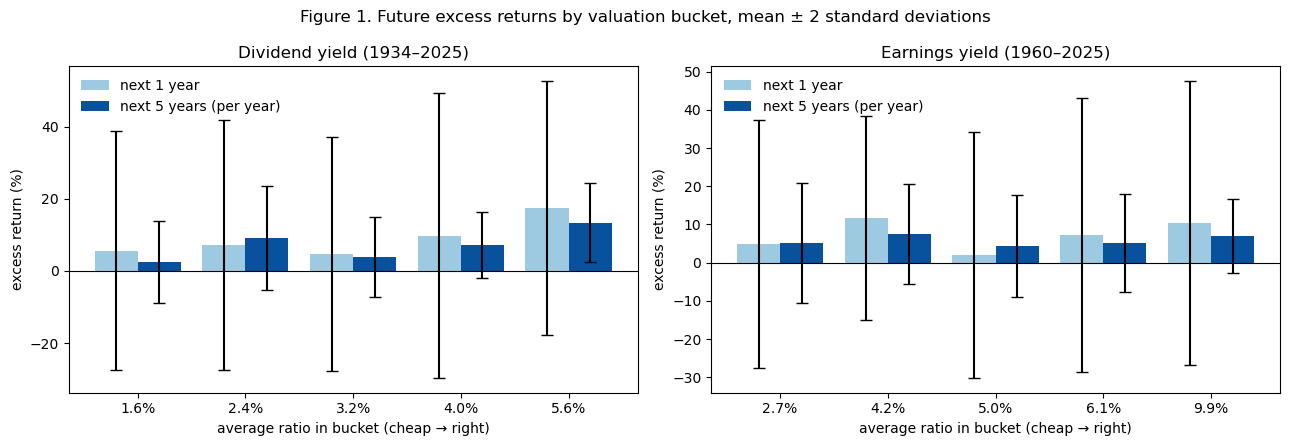

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (t, title) in zip(axes, [(bucket_dy, "Dividend yield (1934–2025)"), (bucket_ey, "Earnings yield (1960–2025)")]):
    pos = np.arange(5)
    ax.bar(pos - 0.2, 100 * t["1Y mean"], 0.4, yerr=200 * t["1Y sd"], capsize=4, label="next 1 year", color="#9ecae1")
    ax.bar(pos + 0.2, 100 * t["5Y/yr mean"], 0.4, yerr=200 * t["5Y/yr sd"], capsize=4, label="next 5 years (per year)", color="#08519c")
    ax.set_xticks(pos, [f"{100 * v:.1f}%" for v in t["avg ratio"]])
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=title, xlabel="average ratio in bucket (cheap → right)", ylabel="excess return (%)")
    ax.legend(frameon=False)
fig.suptitle("Figure 1. Future excess returns by valuation bucket, mean ± 2 standard deviations")
fig.tight_layout()
plt.show()

**What this does:** *Figure 1* plots both valuation sorts, following deck slides 37-39. Error bars are **mean ±2 within-bucket standard deviations**, describing outcome dispersion rather than confidence intervals for the means.

In [18]:
post = d_dy[d_dy["post2011"]]
pd.DataFrame({
    "post-2011 months": post.groupby("bucket", observed=True).size(),
    "post-2011 1Y mean": post.groupby("bucket", observed=True)["fwd_1Y_vw"].mean(),
    "all-years 1Y mean": bucket_dy["1Y mean"],
}).round(3).rename_axis("dividend-yield bucket")

,post-2011 months,post-2011 1Y mean,all-years 1Y mean
dividend-yield bucket,,,
1,71.0,0.085,0.057
2,85.0,0.149,0.072
3,NaN,NaN,0.047
4,NaN,NaN,0.098
5,NaN,NaN,0.175


**What this does:** locates post-2011 months in the dividend-yield buckets and compares their average one-year returns with the full-sample bucket averages. This checks how recent outcomes depart from the historical valuation pattern.

## 6. Returns vs. volatility: GARCH(1,1) (requirement 11)

Monthly CRSP value-weighted returns are fitted by maximum likelihood with a constant mean and normal errors:

$$\sigma^2_{t+1}=\omega+\alpha\varepsilon_t^2+\beta\sigma_t^2.$$

The lecture comparison is in deck slides 41-43 (assignment 31-33).

In [19]:
y = 100 * crsp["vwretd"]                        # percent, for numerical stability

def garch_var(params, e, init=None):
    # Conditional variance path; starts from `init` (default: the sample variance of e).
    w_, a_, b_ = params
    s2 = np.empty_like(e)
    s2[0] = e.var() if init is None else init
    for t in range(1, len(e)):
        s2[t] = w_ + a_ * e[t - 1] ** 2 + b_ * s2[t - 1]
    return s2

def fit_garch(e):
    def neg_loglik(params):
        w_, a_, b_ = params
        if w_ <= 0 or a_ < 0 or b_ < 0 or a_ + b_ >= 1:
            return 1e10
        s2 = garch_var(params, e)
        return 0.5 * np.sum(np.log(2 * np.pi * s2) + e ** 2 / s2)
    res = minimize(neg_loglik, [0.1 * e.var(), 0.1, 0.85], method="Nelder-Mead",
                   options={"maxiter": 10000, "xatol": 1e-8, "fatol": 1e-8})
    assert res.success, res.message
    return res.x

mu = y.mean()
e = (y - mu).to_numpy()
w, a, b = fit_garch(e)
long_run = w / (1 - a - b)
pd.Series({"omega": w, "alpha (news)": a, "beta (memory)": b, "alpha + beta": a + b,
           "half-life of a shock (months)": np.log(0.5) / np.log(a + b),
           "long-run vol (annual, %)": np.sqrt(12 * long_run)}).round(4)

omega                             0.7432
alpha (news)                      0.1403
beta (memory)                     0.8369
alpha + beta                      0.9773
half-life of a shock (months)    30.1443
long-run vol (annual, %)         19.8072
dtype: float64

**What this does:** estimates GARCH on 1926-2025 returns. $\alpha$ measures the response to new squared shocks; $\beta$ carries forward past variance. Their sum measures persistence. The table reports parameters, long-run volatility and the half-life of a variance shock. This full-sample fit is descriptive.

In [20]:
s2 = garch_var((w, a, b), e)
s2_next = w + a * e ** 2 + b * s2              # forecast made at end of month t for month t+1
avg12 = long_run + (s2_next - long_run) * ((a + b) ** np.arange(12)).mean()   # average variance over t+1..t+12

vol = pd.DataFrame(index=crsp.index)
vol["garch_12m"] = np.sqrt(12 * avg12) / 100
vol["garch_1m"] = np.sqrt(12 * s2_next) / 100
dev2 = pd.Series(e ** 2, index=crsp.index)
vol["realized_next_12m"] = np.sqrt(12 * dev2.rolling(12).mean().shift(-12)) / 100
vol["realized_past_12m"] = np.sqrt(12 * dev2.rolling(12).mean()) / 100
vol["abs_next_1m"] = np.sqrt(12) * np.abs(pd.Series(e, index=crsp.index).shift(-1)) / 100

v = vol.dropna()
best_return_corr = extended.xs("1Y", level="horizon")["corr"].abs()
pd.Series({
    "GARCH 12m forecast vs realized next 12m": v["garch_12m"].corr(v["realized_next_12m"]),
    "naive past-12m vol vs realized next 12m": v["realized_past_12m"].corr(v["realized_next_12m"]),
    "GARCH 1m forecast vs |next-month return|": v["garch_1m"].corr(v["abs_next_1m"]),
    "1-year return predictors: median |corr|": best_return_corr.median(),
    "1-year return predictors: largest |corr|": best_return_corr.max(),
    "average GARCH volatility (annual)": vol["garch_1m"].mean(),
}).round(3)

GARCH 12m forecast vs realized next 12m     0.635
naive past-12m vol vs realized next 12m     0.616
GARCH 1m forecast vs |next-month return|    0.408
1-year return predictors: median |corr|     0.167
1-year return predictors: largest |corr|    0.328
average GARCH volatility (annual)           0.169
dtype: float64

**What this does:** compares forecast and realized volatility over the same next 12 months. With monthly data, realized volatility is the annualized **root mean squared deviation from the model's constant mean**, rather than a measure built from daily returns. The forecast is the square root of average predicted variance over that horizon, annualized.

Benchmarks are the same measure over the past 12 months, next-month absolute shocks, and the one-year return-predictor correlations. These compare descriptive associations; they are not identical forecast-evaluation exercises.

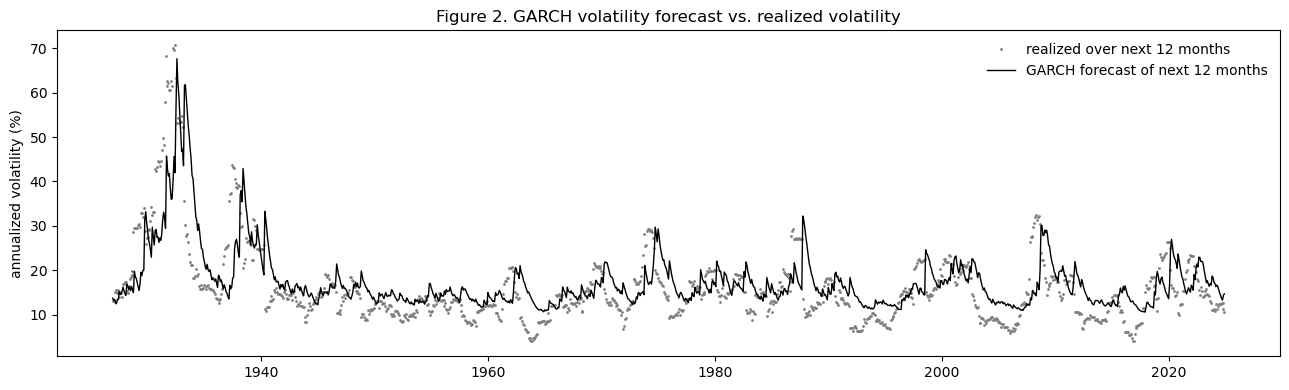

In [21]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(v.index.to_timestamp(), 100 * v["realized_next_12m"], ".", ms=2, color="grey", label="realized over next 12 months")
ax.plot(v.index.to_timestamp(), 100 * v["garch_12m"], color="black", lw=1, label="GARCH forecast of next 12 months")
ax.set(ylabel="annualized volatility (%)", title="Figure 2. GARCH volatility forecast vs. realized volatility")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**What this does:** *Figure 2* places GARCH volatility forecasts beside subsequent realized volatility, following the lecture's line-and-dot comparison.

In [22]:
# Out-of-sample: estimate on 1926-2011 only, keep the parameters fixed, forecast 2012-2025.
train = y.loc[:"2011-12"]
mu_tr = train.mean()
e_all = (y - mu_tr).to_numpy()
e_tr = (train - mu_tr).to_numpy()
w_tr, a_tr, b_tr = fit_garch(e_tr)
s2_all = garch_var((w_tr, a_tr, b_tr), e_all, init=e_tr.var())   # start from the training-sample variance
s2_next_tr = w_tr + a_tr * e_all ** 2 + b_tr * s2_all
lr_tr = w_tr / (1 - a_tr - b_tr)

oos = pd.DataFrame({
    "garch_1m": s2_next_tr,
    "garch_12m": lr_tr + (s2_next_tr - lr_tr) * ((a_tr + b_tr) ** np.arange(12)).mean(),
    "next_sq": pd.Series(e_all ** 2, index=y.index).shift(-1).to_numpy(),
    "realized_next_12m": pd.Series(e_all ** 2, index=y.index).rolling(12).mean().shift(-12).to_numpy(),
}, index=y.index).loc["2012-01":]
const = e_tr.var()                              # benchmark: constant variance from the training sample
d1 = oos.dropna(subset=["next_sq"])
naive_vol = pd.Series(e_all ** 2, index=y.index).rolling(12).mean().loc["2012-01":]   # past-12-month variance
pd.DataFrame({
    "GARCH(1,1)": [((d1["garch_1m"] - d1["next_sq"]) ** 2).mean(),
                   (np.log(d1["garch_1m"]) + d1["next_sq"] / d1["garch_1m"]).mean(),
                   np.sqrt(oos["garch_12m"]).corr(np.sqrt(oos["realized_next_12m"]))],
    "constant variance": [((const - d1["next_sq"]) ** 2).mean(),
                          (np.log(const) + d1["next_sq"] / const).mean(), np.nan],
    "naive past-12m volatility": [np.nan, np.nan, np.sqrt(naive_vol).corr(np.sqrt(oos["realized_next_12m"]))],
}, index=["MSE vs next squared return", "QLIKE", "corr: 12m volatility forecast vs realized volatility"]).round(3).assign(
    **{"note": [f"{len(d1)} forecasts, 2012-2025", "lower is better", f"{oos['realized_next_12m'].notna().sum()} origins"]})

,"GARCH(1,1)",constant variance,naive past-12m volatility,note
MSE vs next squared return,838.794,1045.289,NaN,"167 forecasts, 2012-2025"
QLIKE,3.715,3.951,NaN,lower is better
corr: 12m volatility forecast vs realized volatility,0.282,NaN,0.239,156 origins


**What this does:** estimates parameters on **1926-2011 only**, freezes them, and updates the variance filter with returns observed during 2012-2025. Initialization and the mean also use training data.

One-month variance forecasts are scored against next-month squared surprises using MSE and QLIKE (lower is better), with training-sample constant variance as the benchmark. Twelve-month volatility correlations are compared with a past-12-month forecast. Squared monthly returns are noisy proxies for realized variance; the model is not periodically re-estimated.

## 7. Sensitivity (requirement 12)

The predictability table is repeated under alternative assumptions:

- **Overlap:** twice the Newey-West lags; non-overlapping origins, using the median correlation and ordinary t-statistic across starting-month phases.
- **Returns:** equal-weighted index; nominal returns.
- **Cleaning:** no growth-rate clipping; 5/95 instead of 1/99.
- **Sample:** origins before/from 1990; excluding origins July 2019 - June 2021.

Subperiods classify forecast origins; future outcomes can extend beyond the origin-period boundary.

In [23]:
def nonoverlap(df, x, h, ret="vw"):
    y_ = f"fwd_{hname(h)}_{ret}"
    d = df[[x, y_]].dropna()
    cs, ts = [], []
    for start in range(h):
        s = d.iloc[start::h]
        if len(s) >= 10:
            cs.append(s[x].corr(s[y_]))
            ts.append(sm.OLS(s[y_], sm.add_constant(s[x])).fit().tvalues[x])
    if not cs:                           # too few non-overlapping observations
        return {"corr": np.nan, "t": np.nan}
    return {"corr": np.median(cs), "t": np.median(ts)}

raw_name = lambda x: x + "_raw" if x + "_raw" in panel else x
w5_name = lambda x: x + "_w5" if x + "_w5" in panel else x
covid = (panel.index >= pd.Period("2019-07", "M")) & (panel.index <= pd.Period("2021-06", "M"))
SCENARIOS = {
    "Baseline": lambda x, h: predictive(panel, x, h),
    "NW 2(h-1) lags": lambda x, h: predictive(panel, x, h, lags=2 * (h - 1)),
    "Non-overlapping": lambda x, h: nonoverlap(panel, x, h),
    "Equal-weighted": lambda x, h: predictive(panel, x, h, ret="ew"),
    "Nominal returns": lambda x, h: predictive(panel, x, h, ret="vw_nominal"),
    "No winsorizing": lambda x, h: predictive(panel, raw_name(x), h),
    "Winsorize 5/95": lambda x, h: predictive(panel, w5_name(x), h),
    "Origins before 1990": lambda x, h: predictive(panel[panel.index < pd.Period("1990-01", "M")], x, h),
    "Origins 1990+": lambda x, h: predictive(panel[panel.index >= pd.Period("1990-01", "M")], x, h),
    "Excluding COVID": lambda x, h: predictive(panel[~covid], x, h),
}

def safe(f, x, h):
    try:
        return f(x, h)
    except (ValueError, KeyError):       # predictor has no data in that sub-period
        return {"corr": np.nan, "t": np.nan}

sens = pd.DataFrame([{"predictor": x, "horizon": n, "scenario": s, **safe(f, x, h)}
                     for s, f in SCENARIOS.items() for x in predictors for n, h in HORIZONS.items()])
sig_count = (sens.assign(sig=sens["t"].abs() > 2)
             .pivot_table(index="predictor", columns="scenario", values="sig", aggfunc="sum")
             .reindex(index=predictors, columns=list(SCENARIOS)))
sig_count.index = [LABELS[p] for p in sig_count.index]
sig_count.style.background_gradient(cmap="Blues", vmin=0, vmax=4).format("{:.0f}", na_rep="–") \
    .set_caption("Number of horizons (of 4) with |t| > 2")

scenario,Baseline,NW 2(h-1) lags,Non-overlapping,Equal-weighted,Nominal returns,No winsorizing,Winsorize 5/95,Origins before 1990,Origins 1990+,Excluding COVID
Dividend yield,4,4,4,4,3,4,4,4,3,4
Earnings yield,0,0,0,1,4,0,0,3,0,0
VIX,0,0,0,4,0,0,0,0,0,0
Past volatility (last quarter),1,1,1,2,0,1,1,1,0,0
Consumption–wealth ratio,3,3,1,0,3,3,3,4,0,3
Term spread (10y − 3m),1,1,0,2,1,1,1,1,1,1
Credit spread (BAA − AAA),0,0,0,3,0,0,0,0,2,0
Unemployment rate,2,2,1,2,3,2,2,0,3,1
GDP growth (past year),2,2,1,2,2,2,2,1,3,2
Industrial production (past year),1,0,1,0,0,1,1,0,0,0


**What this does:** repeats all 56 regressions under each specification and counts horizons with $|t|>2$. Darker cells mean more significant horizons. Non-overlapping tests reduce return-window overlap but do not ensure independent errors.

In [24]:
corr_1y = sens[sens["horizon"] == "1Y"].pivot(index="predictor", columns="scenario", values="corr") \
    .reindex(index=predictors, columns=list(SCENARIOS))
corr_1y.index = [LABELS[p] for p in corr_1y.index]
corr_1y.round(2)

scenario,Baseline,NW 2(h-1) lags,Non-overlapping,Equal-weighted,Nominal returns,No winsorizing,Winsorize 5/95,Origins before 1990,Origins 1990+,Excluding COVID
Dividend yield,0.25,0.25,0.24,0.30,0.23,0.25,0.25,0.41,0.35,0.27
Earnings yield,0.10,0.10,0.10,0.21,0.23,0.10,0.10,0.31,0.17,0.12
VIX,0.17,0.17,0.17,0.36,0.15,0.17,0.17,NaN,0.17,0.09
Past volatility (last quarter),0.05,0.05,0.03,0.07,-0.00,0.05,0.05,0.03,0.08,0.02
Consumption–wealth ratio,0.21,0.21,0.22,0.12,0.22,0.21,0.21,0.30,0.05,0.23
Term spread (10y − 3m),0.06,0.06,0.06,0.19,0.02,0.06,0.06,0.22,0.02,0.10
Credit spread (BAA − AAA),0.15,0.15,0.15,0.24,0.15,0.15,0.15,0.13,0.21,0.14
Unemployment rate,0.17,0.17,0.16,0.23,0.20,0.17,0.17,0.09,0.28,0.16
GDP growth (past year),-0.19,-0.19,-0.18,-0.24,-0.18,-0.20,-0.19,-0.19,-0.20,-0.18
Industrial production (past year),-0.14,-0.14,-0.14,-0.11,-0.10,-0.13,-0.17,-0.14,-0.17,-0.11


**What this does:** reports one-year correlations under the same alternatives, checking whether effect sizes change alongside statistical significance.

In [25]:
# Robustness: dividend yield built like the earnings yield (Compustat dividends / CRSP market value).
panel["dy_compustat"] = dy_compustat
dy_alt = pd.DataFrame({name: {**{k: v for k, v in predictive(panel, col, h).items() if k in ("corr", "t", "start")}}
                       for name, h in HORIZONS.items()
                       for col in ["dy_compustat"]}).T
dy_main = pd.DataFrame({name: {k: v for k, v in predictive(panel, "div_yield", h).items() if k in ("corr", "t", "start")}
                        for name, h in HORIZONS.items()}).T
pd.concat({"CRSP index (main)": dy_main, "Compustat dvc / CRSP market value": dy_alt}, axis=1)

CRSP index (main)                    Compustat dvc / CRSP market value  \
                corr         t    start                              corr   
1Q            0.1177  2.457402  1933-12                          0.074422   
1Y          0.250639  3.118304  1933-12                          0.149414   
2Y          0.328024  3.206949  1933-12                          0.128907   
5Y          0.471229  3.791342  1933-12                          0.210666   

                       
           t    start  
1Q    1.3512  1960-06  
1Y  1.551857  1960-06  
2Y  1.070773  1960-06  
5Y  1.649025  1960-06

**What this does:** compares the main dividend yield with common dividends from Compustat divided by matched CRSP market value. The alternative uses the earnings yield's six-month lag and 500-firm minimum, starting in 1960.

The displayed estimates have different sample starts, so construction and sample effects must be distinguished when interpreting the comparison. Section 9 discusses the common-period check and the importance of early observations.

## 8. Bad times: downturns and the post-2011 question

Months are classified **at the forecast origin**, before the future return window:

- **NBER recession (`USREC`):** historical economic downturns. Only two months occur after 2011, so recession comparisons use the longer history. This is an ex-post classification, not a trading signal.
- **Drawdown of at least 10%:** the total-return index is at least 10% below its previous peak. Post-2011 coverage is 21 months across five episodes.
- **High VIX:** month-end VIX exceeds the 75th percentile of earlier months, requiring five years of history. The expanding threshold avoids future VIX information. Post-2011 coverage is 24 months across nine episodes.

Drawdowns and high VIX measure market conditions; they do not replace an economic-recession definition.

### 8a. Post-2011 on its own

In [26]:
post2011 = panel[panel["post2011"]]
post_only = run_table(post2011)
post_only["independent windows"] = post_only["n"] / post_only.index.get_level_values("horizon").map(HORIZONS)
slide_style(post_only, "Origins Jan 2012 onward only: correlation with future excess return (Newey-West t-stat)")

horizon,1Q,1Y,2Y,5Y
Dividend yield,0.21 (2.02),0.47 (2.92),0.60 (4.39),0.57 (2.71)
Earnings yield,0.19 (2.02),0.49 (3.65),0.60 (6.02),0.21 (2.46)
VIX,0.29 (2.68),0.34 (1.57),0.15 (1.29),0.30 (5.01)
Past volatility (last quarter),0.15 (1.35),0.21 (1.30),0.22 (3.16),0.14 (3.92)
Consumption–wealth ratio,0.28 (1.82),0.26 (1.41),-0.08 (-0.26),0.08 (0.97)
Term spread (10y − 3m),-0.10 (-1.10),-0.21 (-1.75),-0.42 (-3.12),-0.19 (-1.41)
Credit spread (BAA − AAA),0.12 (1.14),0.47 (2.95),0.66 (6.11),0.47 (8.75)
Unemployment rate,0.25 (2.99),0.34 (3.27),-0.09 (-0.48),0.12 (1.60)
GDP growth (past year),-0.36 (-3.16),-0.49 (-5.78),-0.12 (-0.67),-0.25 (-1.47)
Industrial production (past year),-0.24 (-2.54),-0.58 (-6.91),-0.26 (-1.98),-0.41 (-1.93)


**What this does:** estimates the table using forecast origins from January 2012 onward, without conditioning on the state. Approximate non-overlapping-window counts are stored in `post_only`: about 55 at one quarter, 13 at one year and fewer than two at five years. The long-horizon results are descriptive because the sample is too short for dependable inference.

### 8b. Downturn vs. normal months: interaction regressions

The predictive regression adds state $S_t$ (1 in a downturn) and its interaction with the predictor:

$$R^e_{t\to t+h}=a+b x_t+c S_t+d x_tS_t+\varepsilon.$$

The coefficient $d$ measures a change in slope, not directly a change in correlation. Newey-West inference uses $h-1$ lags; both states must contain at least 12 observations. That minimum permits estimation, but does not guarantee adequate statistical power.

In [27]:
tr = (1 + panel["vwretd"]).cumprod()
panel["downturn_drawdown"] = (tr / tr.cummax() - 1) <= -0.10
vix_cut = panel["vix"].expanding(min_periods=60).quantile(0.75).shift(1)   # 75th pct of earlier months only
panel["downturn_vix"] = (panel["vix"] > vix_cut).astype(float).where(vix_cut.notna() & panel["vix"].notna())
post2011 = panel[panel["post2011"]]

def state_test(df, x, h, state):
    y_ = f"fwd_{hname(h)}_vw"
    d = df[[x, y_, state]].dropna()
    s = d[state].astype(float)
    out = {"downturn obs": int(s.sum()), "normal obs": int((1 - s).sum())}
    if s.sum() < 12 or (1 - s).sum() < 12:
        return {**out, "corr normal": np.nan, "corr downturn": np.nan, "interaction t": np.nan, "interaction p": np.nan}
    X = pd.DataFrame({"const": 1.0, "x": d[x], "s": s, "xs": d[x] * s})
    fit = sm.OLS(d[y_], X).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1})
    return {**out, "corr normal": d.loc[s == 0, x].corr(d.loc[s == 0, y_]),
            "corr downturn": d.loc[s == 1, x].corr(d.loc[s == 1, y_]),
            "interaction t": fit.tvalues["xs"], "interaction p": fit.pvalues["xs"]}

TESTS = {
    "Full sample, NBER recession": (panel, "downturn_nber"),
    "Full sample, drawdown ≥ 10%": (panel, "downturn_drawdown"),
    "Post-2011, drawdown ≥ 10%": (post2011, "downturn_drawdown"),
    "Post-2011, high VIX": (post2011, "downturn_vix"),
}
states = pd.DataFrame([{"test": name, "predictor": x, "horizon": n, **state_test(df, x, h, s)}
                       for name, (df, s) in TESTS.items() for x in predictors for n, h in HORIZONS.items()])

def summarize(g):
    ok = g.dropna(subset=["interaction t"])
    return pd.Series({
        "predictors tested": len(ok),
        "median downturn obs": ok["downturn obs"].median(),
        "avg |corr| normal": ok["corr normal"].abs().mean(),
        "avg |corr| downturn": ok["corr downturn"].abs().mean(),
        "stronger in downturn": (ok["corr downturn"].abs() > ok["corr normal"].abs()).sum(),
        "significant change (|t|>2)": (ok["interaction t"].abs() > 2).sum(),
    })

state_summary = states.groupby(["test", "horizon"], sort=False)[states.columns.drop(["test", "horizon"])].apply(summarize)
state_summary.round(2)

predictors tested  median downturn obs  \
test                        horizon                                           
Full sample, NBER recession 1Q                    14.0                124.0   
                            1Y                    14.0                124.0   
                            2Y                    14.0                124.0   
                            5Y                    14.0                124.0   
Full sample, drawdown ≥ 10% 1Q                    14.0                229.0   
                            1Y                    14.0                229.0   
                            2Y                    14.0                229.0   
                            5Y                    14.0                213.0   
Post-2011, drawdown ≥ 10%   1Q                    13.0                 21.0   
                            1Y                    13.0                 21.0   
                            2Y                    13.0                 21.0   
                            5Y                     0.0                  NaN   
Post-2011, high VIX         1Q                    13.0                 24.0   
                            1Y                    13.0                 23.0   
                            2Y                    13.0                 23.0   
                            5Y                    13.0                 12.0   

                                     avg |corr| normal  avg |corr| downturn  \
test                        horizon                                           
Full sample, NBER recession 1Q                    0.09                 0.21   
                            1Y                    0.14                 0.24   
                            2Y                    0.14                 0.24   
                            5Y                    0.18                 0.28   
Full sample, drawdown ≥ 10% 1Q                    0.10                 0.12   
                            1Y                    0.14                 0.18   
                            2Y                    0.17                 0.16   
                            5Y                    0.20                 0.26   
Post-2011, drawdown ≥ 10%   1Q                    0.16                 0.39   
                            1Y                    0.36                 0.41   
                            2Y                    0.35                 0.33   
                            5Y                     NaN                  NaN   
Post-2011, high VIX         1Q                    0.09                 0.43   
                            1Y                    0.29                 0.52   
                            2Y                    0.36                 0.45   
                            5Y                    0.26                 0.31   

                                     stronger in downturn  \
test                        horizon                         
Full sample, NBER recession 1Q                       12.0   
                            1Y                        9.0   
                            2Y                        8.0   
                            5Y                       10.0   
Full sample, drawdown ≥ 10% 1Q                        8.0   
                            1Y                        8.0   
                            2Y                        6.0   
                            5Y                        9.0   
Post-2011, drawdown ≥ 10%   1Q                       11.0   
                            1Y                        7.0   
                            2Y                        7.0   
                            5Y                        0.0   
Post-2011, high VIX         1Q                       11.0   
                            1Y                       11.0   
                            2Y                        9.0   
                            5Y                        7.0   

                                     significant change (|t|>2)  
test                      

**What this does:** builds the market-state indicators and runs each predictor-horizon interaction. The summary reports normal/downturn correlations, how often the absolute correlation is larger in downturns, and significant slope changes. Historical NBER tests and recent market-stress tests remain separate.

In [28]:
detail = states[states["horizon"] == "1Y"].copy()
detail["cell"] = detail.apply(lambda r: "–" if pd.isna(r["interaction t"]) else
                              f"{r['corr normal']:.2f} / {r['corr downturn']:.2f} ({r['interaction t']:.1f})", axis=1)
detail = detail.pivot(index="predictor", columns="test", values="cell").reindex(index=predictors, columns=list(TESTS))
detail.index = [LABELS[p] for p in detail.index]
detail.style.set_caption("1-year horizon: corr normal / corr downturn (interaction t)")

test,"Full sample, NBER recession","Full sample, drawdown ≥ 10%","Post-2011, drawdown ≥ 10%","Post-2011, high VIX"
Dividend yield,0.15 / 0.50 (2.3),0.23 / 0.24 (0.0),0.44 / 0.72 (1.4),0.45 / 0.71 (2.1)
Earnings yield,-0.06 / 0.45 (3.2),0.02 / 0.24 (1.4),0.50 / 0.35 (0.1),0.54 / 0.58 (1.2)
VIX,0.11 / 0.60 (3.1),0.00 / 0.34 (1.8),0.24 / 0.44 (0.6),0.08 / 0.52 (2.1)
Past volatility (last quarter),-0.00 / 0.05 (0.6),-0.00 / 0.03 (0.3),0.17 / 0.03 (-0.6),0.06 / 0.27 (1.3)
Consumption–wealth ratio,0.26 / 0.06 (-0.5),0.28 / 0.08 (-0.7),–,–
Term spread (10y − 3m),0.07 / -0.05 (-0.5),0.08 / -0.06 (-0.9),-0.15 / -0.15 (-0.1),-0.17 / -0.59 (-2.3)
Credit spread (BAA − AAA),0.09 / 0.14 (0.2),-0.04 / 0.24 (1.8),0.41 / 0.57 (2.0),0.37 / 0.69 (4.5)
Unemployment rate,0.15 / 0.22 (0.8),0.11 / 0.30 (1.6),0.48 / 0.26 (1.2),0.20 / 0.49 (1.0)
GDP growth (past year),-0.13 / -0.22 (-0.9),-0.15 / -0.23 (-0.8),-0.57 / -0.15 (0.5),-0.49 / -0.47 (0.1)
Industrial production (past year),-0.05 / -0.25 (-1.6),-0.09 / -0.20 (-0.5),-0.60 / -0.65 (-1.7),-0.46 / -0.68 (-1.1)


**What this does:** displays the one-year results for each predictor: normal correlation / downturn correlation (interaction t-statistic). This separates changes in association from the pooled averages.

### 8c. Placebo test: is the downturn gap unusual?

Small samples tend to produce larger absolute sample correlations. The downturn groups are much smaller than the normal groups, so a larger average $|\mathrm{corr}|$ alone is insufficient evidence.

The diagnostic circularly shifts state labels, preserving their overall frequency and clustering, and recomputes the gap in average absolute correlations. The reported p-value is the fraction of shifted gaps at least as large as the observed one. This checks whether the actual timing is unusual under that reference distribution; it relies on shifting labels being a meaningful comparison across time.

In [29]:
def corr_gap(df, state_values, h, ret="vw", col=lambda x: x):
    # Average |corr| in downturn months minus in normal months, across predictors.
    y_ = df[f"fwd_{hname(h)}_{ret}"].to_numpy()
    gaps_down, gaps_norm = [], []
    for x in predictors:
        xv = df[col(x)].to_numpy()
        ok = ~np.isnan(xv) & ~np.isnan(y_) & ~np.isnan(state_values)
        down, norm = ok & (state_values == 1), ok & (state_values == 0)
        if down.sum() >= 12 and norm.sum() >= 12:
            gaps_down.append(abs(np.corrcoef(xv[down], y_[down])[0, 1]))
            gaps_norm.append(abs(np.corrcoef(xv[norm], y_[norm])[0, 1]))
    return np.mean(gaps_down) - np.mean(gaps_norm) if gaps_down else np.nan

def placebo(df, state, h, **kw):
    s = df[state].to_numpy(dtype=float)
    actual = corr_gap(df, s, h, **kw)
    fake = np.array([corr_gap(df, np.roll(s, k), h, **kw) for k in range(1, len(s))])
    fake = fake[~np.isnan(fake)]
    return {"gap (down − normal)": actual, "placebo median gap": np.median(fake),
            "p-value": (fake >= actual).mean(), "placebos": len(fake)}

excl_2020 = post2011[post2011.index.year != 2020]
PLACEBO_TESTS = {**TESTS,
                 "Post-2011, drawdown ≥ 10%, excl. 2020": (excl_2020, "downturn_drawdown"),
                 "Post-2011, high VIX, excl. 2020": (excl_2020, "downturn_vix")}
placebo_table = pd.DataFrame([{"test": name, "horizon": n, **placebo(df, s, h)}
                              for name, (df, s) in PLACEBO_TESTS.items() for n, h in HORIZONS.items() if h <= 12])
placebo_table.set_index(["test", "horizon"]).round(3)

gap (down − normal)  \
test                                  horizon                        
Full sample, NBER recession           1Q                     0.119   
                                      1Y                     0.108   
Full sample, drawdown ≥ 10%           1Q                     0.017   
                                      1Y                     0.032   
Post-2011, drawdown ≥ 10%             1Q                     0.224   
                                      1Y                     0.050   
Post-2011, high VIX                   1Q                     0.335   
                                      1Y                     0.232   
Post-2011, drawdown ≥ 10%, excl. 2020 1Q                     0.327   
                                      1Y                     0.187   
Post-2011, high VIX, excl. 2020       1Q                     0.306   
                                      1Y                     0.155   

                                               placebo median gap  p-value  \
test                                  horizon                                
Full sample, NBER recession           1Q                    0.038    0.062   
                                      1Y                    0.053    0.190   
Full sample, drawdown ≥ 10%           1Q                    0.012    0.460   
                                      1Y                    0.016    0.359   
Post-2011, drawdown ≥ 10%             1Q                    0.090    0.132   
                                      1Y                   -0.002    0.406   
Post-2011, high VIX                   1Q                    0.059    0.012   
                                      1Y                    0.047    0.114   
Post-2011, drawdown ≥ 10%, excl. 2020 1Q                    0.116    0.065   
                                      1Y                    0.058    0.282   
Post-2011, high VIX, excl. 2020       1Q                    0.126    0.052   
                                      1Y                    0.066    0.333   

                                               placebos  
test                                  horizon            
Full sample, NBER recession           1Q           1199  
                                      1Y           1199  
Full sample, drawdown ≥ 10%           1Q           1199  
                                      1Y           1199  
Post-2011, drawdown ≥ 10%             1Q            167  
                                      1Y            160  
Post-2011, high VIX                   1Q            167  
                                      1Y            167  
Post-2011, drawdown ≥ 10%, excl. 2020 1Q            155  
                                      1Y            142  
Post-2011, high VIX, excl. 2020       1Q            155  
                                      1Y            141

**What this does:** runs the placebo at one quarter and one year for each state definition, then excludes 2020 from the recent tests. The placebo median gap indicates how much apparent downturn predictability can arise from the unequal group sizes.

### 8d. Multiple testing

Each interaction family has up to 56 tests (14 predictors times four horizons). Benjamini-Hochberg adjustment is applied within each family, comparing raw p-values with adjusted values at 5%. It addresses multiple testing, conditional on the underlying regression p-values being valid and the procedure's dependence assumptions.

In [30]:
fdr = states.dropna(subset=["interaction p"]).copy()
fdr["q"] = fdr.groupby("test")["interaction p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
fdr_summary = fdr.groupby(["test", "horizon"], sort=False).agg(
    tests=("q", "size"), **{"p < 0.05": ("interaction p", lambda p: (p < 0.05).sum()),
                            "q < 0.05 (after FDR)": ("q", lambda q: (q < 0.05).sum())})
fdr_summary

tests  p < 0.05  q < 0.05 (after FDR)
test                        horizon                                       
Full sample, NBER recession 1Q          14         2                     0
                            1Y          14         3                     0
                            2Y          14         1                     0
                            5Y          14         3                     0
Full sample, drawdown ≥ 10% 1Q          14         0                     0
                            1Y          14         0                     0
                            2Y          14         1                     0
                            5Y          14         1                     0
Post-2011, drawdown ≥ 10%   1Q          13         5                     4
                            1Y          13         2                     1
                            2Y          13         2                     1
Post-2011, high VIX         1Q          13         6                     2
                            1Y          13         5                     1
                            2Y          13         3                     0
                            5Y          13         4                     1

**What this does:** counts significant interactions before and after adjustment. This is different from the placebo: the interactions test individual slope changes, while the placebo examines an aggregate correlation gap. Neither resolves the limited number of post-2011 stress episodes, and agreement between them is not required.

### 8e. Sensitivity of the economic answer

In [31]:
ALTERNATIVES = {
    "Baseline": {},
    "Equal-weighted": {"ret": "ew"},
    "Nominal returns": {"ret": "vw_nominal"},
    "No winsorizing": {"col": raw_name},
    "Winsorize 5/95": {"col": w5_name},
}
answer_rows = []
for test in ["Full sample, NBER recession", "Post-2011, high VIX"]:
    df, state = TESTS[test]
    variants = {**{k: (df, kw) for k, kw in ALTERNATIVES.items()},
                "Excluding 2020": (df[df.index.year != 2020], {})}
    for alt, (d_alt, kw) in variants.items():
        for n, h in [("1Q", 3), ("1Y", 12)]:
            res = placebo(d_alt, state, h, **kw)
            answer_rows.append({"test": test, "assumption": alt, "horizon": n,
                                "gap": res["gap (down − normal)"], "p-value": res["p-value"]})
answer = pd.DataFrame(answer_rows).pivot_table(index=["test", "assumption"], columns="horizon",
                                                values=["gap", "p-value"], sort=False)
answer.round(3)

gap        p-value       
horizon                                         1Q     1Y      1Q     1Y
test                        assumption                                  
Full sample, NBER recession Baseline         0.119  0.108   0.062  0.190
                            Equal-weighted   0.135  0.119   0.035  0.128
                            Nominal returns  0.080  0.106   0.294  0.336
                            No winsorizing   0.119  0.108   0.063  0.188
                            Winsorize 5/95   0.117  0.111   0.056  0.171
                            Excluding 2020   0.131  0.123   0.046  0.152
Post-2011, high VIX         Baseline         0.335  0.232   0.012  0.114
                            Equal-weighted   0.225  0.197   0.054  0.138
                            Nominal returns  0.331  0.238   0.018  0.114
                            No winsorizing   0.334  0.229   0.018  0.114
                            Winsorize 5/95   0.333  0.234   0.012  0.108
                            Excluding 2020   0.306  0.155   0.052  0.333

**What this does:** repeats the historical NBER and recent high-VIX placebos with alternative indexes, nominal returns, different clipping and 2020 excluded. Lag length cannot affect this correlation-based diagnostic. The table shows whether the economic answer changes when the assumptions change.

## 9. Summary of results

**Sample.** Monthly CRSP value-weighted excess returns through Dec 2025, with predictor-specific histories. The earliest excess-return windows start in 1934; earnings yield begins in June 1960, term spread in 1982, oil growth in 1987 and VIX in 1990. Lagged cay ends in Feb 2020. The cleaning log reports 41 steps.

**1. The main lecture pattern survives, with important differences.** Signs agree in **52 of 56** entries in both historical and extended samples. In the sign disagreements, one correlation is within 0.02 of zero. Average absolute correlation gaps are usually 0.04-0.10; earnings yield and cay differ more. Selected extended estimates are below; Section 4 displays every comparison.

| Predictor | 1-quarter corr (t) | 1-year corr (t) | 2-year corr (t) | 5-year corr (t) |
|---|---|---|---|---|
| Dividend yield | 0.12 (2.46) | 0.25 (3.12) | 0.33 (3.21) | 0.47 (3.79) |
| Earnings yield | 0.06 (1.10) | 0.10 (1.03) | 0.10 (0.96) | 0.12 (0.97) |
| Consumption-wealth ratio | 0.13 (2.61) | 0.21 (2.27) | 0.27 (2.08) | 0.26 (1.54) |

Dividend yield is close to the lecture's 0.12, 0.23, 0.33 and 0.49. Earnings yield is much weaker than its 0.18-0.48 lecture correlations and is insignificant at every horizon. Ours uses one year's Compustat earnings; a different earnings definition, coverage or sample could explain the gap. The lecture bucket charts use smoothed Shiller earnings, but the predictability table's exact definition is unstated.

Our t-statistics are generally larger. Changing frequency and sample moves them toward the lecture's, but does not identify the lecture method. Index coverage, the bill-return proxy, revisions and standard-error choices may also matter. Matching a correlation does not establish identical replication.

**2. Adding post-2011 data weakens several historical relationships.** Dividend-yield correlations fall from 0.31 to 0.25 at one year and 0.58 to 0.47 at five years, retaining their positive signs and significance. Five-year cay falls from 0.39 to 0.26; one-year term spread from 0.20 to 0.06. Several macro variables cross $|t|=2$ with relatively small correlation changes. Excluding COVID-era origins leaves the broad pattern intact.

Within 2012-2025 alone, the median absolute one-year correlation is about 0.34 and dividend yield remains positive. These larger estimates do not establish stronger recent predictability: only about 13 non-overlapping years, and fewer than two five-year windows, are available.

**3. The DDM interpretation is supported more strongly at long horizons.** At one year, high dividend yields precede both higher returns and lower dividend growth. At five years, return correlation rises to 0.47 while dividend-growth correlation is -0.16 (t = -1.53). This is consistent with persistent expected-return variation explaining more of long-horizon yield movements, although it is not a causal decomposition.

A persistent yield can add a small predictable component to several successive returns, while unpredictable shocks partly average out. That explains why valuation predictability can rise with horizon. Overlap also reduces independent information, so rising correlations should not be read as equally strong increases in statistical certainty.

**4. Valuation buckets show a signal with substantial noise.**

| Dividend-yield bucket | Average next-year excess return | Average next-five-year excess return, per year |
|---|---|---|
| Lowest yield (most expensive) | 5.7% | 2.5% |
| Highest yield (cheapest) | 17.5% | 13.4% |

These extremes resemble the lecture, but the middle buckets are not ordered. The ±2 SD bands overlap throughout; even the most expensive bucket spans approximately -28% to +39% at one year. About 15% of one-year outcomes in the cheapest bucket are negative. Dividend yield explains only about $0.25^2\approx6\%$ of one-year return variation. Earnings-yield buckets are flatter: five-year annual excess returns rise from 5.2% to 7.1% between the extremes.

Every post-2011 origin with a complete one-year return lies in the two most expensive dividend-yield buckets, yet their returns exceed the historical bucket averages (8.5% vs 5.7%; 14.9% vs 7.2%). Expensive markets can keep rising. Buybacks are a possible reason dividends alone may miss changing payouts, but this notebook does not test that explanation.

**5. Volatility is persistent and more predictable over the long history.** GARCH estimates $\alpha\approx0.14$, $\beta\approx0.84$ and persistence of 0.98, implying a variance-shock half-life of about 30 months. Average forecast volatility is 17% a year, versus 15.3% in the lecture.

| Comparison | GARCH | Benchmark |
|---|---|---|
| Full-sample 12-month volatility correlation | 0.64 | 0.62, past-12-month volatility |
| Post-2011 12-month volatility correlation, frozen pre-2012 model | 0.28 | 0.24, past-12-month volatility |
| Post-2011 one-month variance MSE | 839 | 1,045, training constant variance |
| Post-2011 one-month QLIKE | 3.71 | 3.95, training constant variance |

The full-history volatility correlation exceeds the median 0.17 and maximum 0.33 for one-year return predictors. It is numerically close to the lecture's 0.63, but our monthly-data proxy need not match its realized-volatility measure. The historical-volatility benchmark performs almost as well, showing the importance of persistence. Out of sample, GARCH has lower losses than a constant forecast and a somewhat higher correlation than the naive forecast. No formal test of forecast-loss differences is reported.

After 2011, volatility correlation is only 0.28, also about 0.28 using full-sample parameters over those years. Performance therefore varies substantially by period. The model does not anticipate sudden spikes a year ahead, so the full-history result should not be presented as a reliable market-timing rule.

**6. Sensitivity preserves some findings, but sample dependence matters.** The entries below count horizons with $|t|>2$ out of four.

| Predictor | Baseline | Double NW lags | Non-overlapping | Equal-weighted | Origins 1990+ |
|---|---|---|---|---|---|
| Dividend yield | 4 | 4 | 4 | 4 | 3 |
| Earnings yield | 0 | 0 | 0 | 1 | 0 |
| cay | 3 | 3 | 1 | 0 | 0 |
| GDP growth | 2 | 2 | 1 | 2 | 3 |
| Oil change | 4 | 4 | 1 | 2 | 4 |
| Past one-year return | 3 | 3 | 0 | 3 | 1 |

Dividend yield is significant at three or four horizons across these specifications. However, the two dividend-yield constructions correlate about 0.99 over their common period, and both give weaker, insignificant results from 1960 onward. For the CRSP yield over that period, the four t-statistics are approximately 1.33, 1.50, 1.14 and 1.63. The early sample contributes substantially to full-history significance; changing construction does not resolve that sample dependence.

Doubling lags or varying growth-rate clipping changes little. Non-overlapping tests weaken most other results, indicating sensitivity to how overlapping observations are used. Earnings yield becomes significant mainly for nominal returns or pre-1990 origins and correlates 0.69 with the bill rate, consistent with interest-rate variation contributing to its nominal-return relationship. VIX and credit spread become significant for equal-weighted returns, while cay loses significance after 1990. The full tables in Section 7 cover all predictors and alternatives.

**7. Downturn evidence is suggestive at short horizons and fragile.**

| State and sample | One-quarter placebo p | One-year placebo p |
|---|---|---|
| NBER recessions, full history | 0.06 | 0.19 |
| Post-2011 drawdowns | 0.13 | 0.41 |
| Post-2011 high VIX | 0.01 | 0.11 |

Historically, average absolute one-quarter correlation is 0.21 in recessions against 0.09 in normal months, stronger for 12 of 14 predictors. Individual historical interaction tests do not survive the FDR adjustment. The aggregate placebo result is marginal at one quarter and insignificant at one year; full-history drawdowns also provide little evidence (p at least 0.36).

Post-2011 high-VIX months have average absolute one-quarter correlation of 0.43 against 0.09. The placebo p-value remains around 0.01-0.02 with nominal returns or alternative clipping, but rises to about 0.05 with equal weights or 2020 excluded. At one year it is never significant. Historical recession results are also assumption-dependent: one-quarter p-values are about 0.035-0.06 except for nominal returns (0.29).

Some recent individual interactions survive FDR adjustment, but they use only 20-25 overlapping stress months. An extreme five-year interaction t-statistic on about a dozen stressed origins illustrates the limited information. FDR adjustment cannot repair unreliable underlying p-values. The placebo examines a different statistic and has its own assumptions. With multiple state definitions and horizons, VIX used as both predictor and state variable, and only nine recent stress episodes, these findings warrant caution.

## 10. Conclusion, implications for the audience, and limitations

**Conclusion.** Stronger predictability during **post-2011 economic recessions cannot be assessed reliably**: only two NBER recession months occur. High-VIX periods provide suggestive one-quarter evidence, but it weakens under alternative assumptions and does not persist at one year. Market drawdowns show no clear difference. The extension therefore supports a narrower statement about financial stress, rather than a general claim about recession predictability.

**For pension funds and long-term investors.** Valuation ratios can inform long-run return expectations: high dividend yields have preceded higher average returns, but dispersion is wide and significance depends partly on early observations. Expensive markets continued rising after 2011. The evidence does not justify a mechanical equity-allocation rule or establish that investors could have earned abnormal returns after costs.

Volatility forecasts may help describe changing portfolio risk. GARCH improves on a constant-variance benchmark out of sample, although the historical-volatility benchmark is competitive and recent correlations are much weaker. Any exposure rule would need its own evaluation of returns, trading costs and investor constraints; that strategy is not tested here.

**Limitations.**

1. Predictor histories differ, so cross-predictor comparisons also reflect sample differences. The strongest dividend-yield significance relies partly on 1934-1959.
2. Excess returns begin in 1934 because of the bill series. Its yield conversion approximates monthly bill returns. The supplied term-spread and oil histories are shorter than some alternative sources.
3. Six-month accounting lags approximate availability; Compustat, FRED and cay contain revisions. This is a historical association study, not a complete real-time forecasting experiment.
4. Matched-firm earnings coverage, the 500-firm minimum and the dividend-yield approximation can affect valuation estimates. Exact lecture definitions are not available for every variable.
5. Long return windows overlap. HAC, alternative lags and non-overlapping tests help assess dependence but cannot create more independent history. Monthly returns also give a noisy realized-volatility proxy.
6. Recent stress observations cluster in a handful of episodes. Multiple testing and a small recession sample limit inference, while the circular-shift placebo depends on its reference distribution being appropriate.

## 11. Requirements checklist and reproducibility

| # | Requirement | Where |
|---|---|---|
| 1 | Economic question, rationale and audience | Section 1 |
| 2 | Sources and predictor construction | Sections 2a-2c |
| 3 | Total returns, compounding and nominal/excess distinction | Sections 2 and 2e |
| 4 | Missing values, duplicates, outliers, alignment and observation counts | Sections 2a-2f |
| 5 | Correlations, t-statistics and overlapping observations | Section 3 |
| 6 | Table in lecture format | Section 3 |
| 7 | Sample extension | Section 3; coverage limitations in Section 10 |
| 8 | Lecture comparison and explanations | Sections 4 and 9 |
| 9 | DDM interpretation and horizon effects | Sections 5 and 9 |
| 10 | Five buckets and ±2 SD bands | Section 5, Figure 1; Section 9 |
| 11 | GARCH, realized volatility and return predictability | Sections 6 and 9 |
| 12 | Alternative assumptions and effect on the conclusion | Sections 7-9 |

**Reproducibility.** Inputs are the files in `data/`, read with relative paths. Run top to bottom; nothing is downloaded or written. Required packages: pandas 2.3, numpy 2.3, statsmodels 0.14, scipy 1.16, matplotlib 3.10, jinja2 and IPython/Jupyter (see README).

**Authorship.** Merges Kamakshi's and Bodhana's versions, retaining the shared data, lecture replication, cleaning, interpretation, sensitivity, out-of-sample GARCH and downturn tests.